# Arbre de décision 

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from dotenv import load_dotenv

load_dotenv()
DATA_DIR = os.getenv("DATA_DIR")

col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
diabetes_data = pd.read_csv(os.path.join(DATA_DIR, "diabetes.csv"),
                            header=None, names=col_names, skiprows=1)
print(diabetes_data.shape)        # (768, 9)
print(diabetes_data.head())
print(diabetes_data.dtypes)       # every column should be int64 or float64, not object

(768, 9)
   pregnant  glucose  bp  skin  insulin   bmi  pedigree  age  label
0         6      148  72    35        0  33.6     0.627   50      1
1         1       85  66    29        0  26.6     0.351   31      0
2         8      183  64     0        0  23.3     0.672   32      1
3         1       89  66    23       94  28.1     0.167   21      0
4         0      137  40    35      168  43.1     2.288   33      1
pregnant      int64
glucose       int64
bp            int64
skin          int64
insulin       int64
bmi         float64
pedigree    float64
age           int64
label         int64
dtype: object


### Q9 a) Exploration des données

Le jeu de données contient **768 patientes** décrites par 8 variables médicales et une étiquette `label` (1 = diabétique).

**1. Répartition des classes :** 500 non diabétiques (65 %) contre 268 diabétiques (35 %) → classes **déséquilibrées**. Un modèle qui prédirait toujours « 0 » obtiendrait déjà 65 % d'accuracy.

**2. Distributions (histogrammes) :**
- **Glucose, pression (bp) et IMC** suivent une distribution à peu près en cloche (centrées vers 110–120, 70 et 32).
- **Grossesses, insuline, pedigree et âge** sont **asymétriques à droite** : la plupart des valeurs sont faibles, avec une longue traîne (âge minimum 21 ans).
- **Valeurs nulles impossibles** : on voit des barres isolées à 0 pour le glucose (5), la pression (35), le pli cutané (227), l'insuline (374) et l'IMC (11). Une pression ou un IMC nul est biologiquement impossible : ces zéros représentent des **données manquantes**.

**3. Corrélations avec le diabète (`label`) :**
- **Glucose (0,47)** : variable la plus liée au diabète.
- Puis **IMC (0,29)**, **âge (0,24)**, **grossesses (0,22)** et **pedigree (0,17)**.
- Pression (0,07) et pli cutané (0,07) sont presque non corrélés (aussi à cause des nombreux zéros).

**4. Corrélations entre variables :** âge–grossesses (0,54), pli cutané–insuline (0,44), pli cutané–IMC (0,39) et glucose–insuline (0,33) : certaines variables apportent en partie la même information.

**Conséquence pour l'arbre :** on s'attend à ce que le **glucose** soit utilisé pour la première division (racine), puis l'IMC et l'âge. Les arbres ne nécessitent pas de mise à l'échelle des variables, car chaque division compare une seule variable à un seuil.

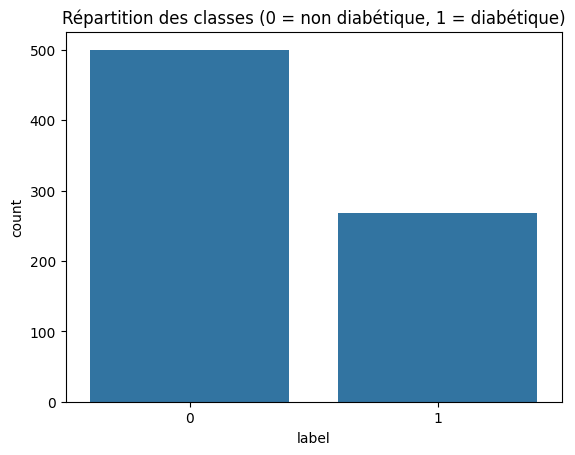

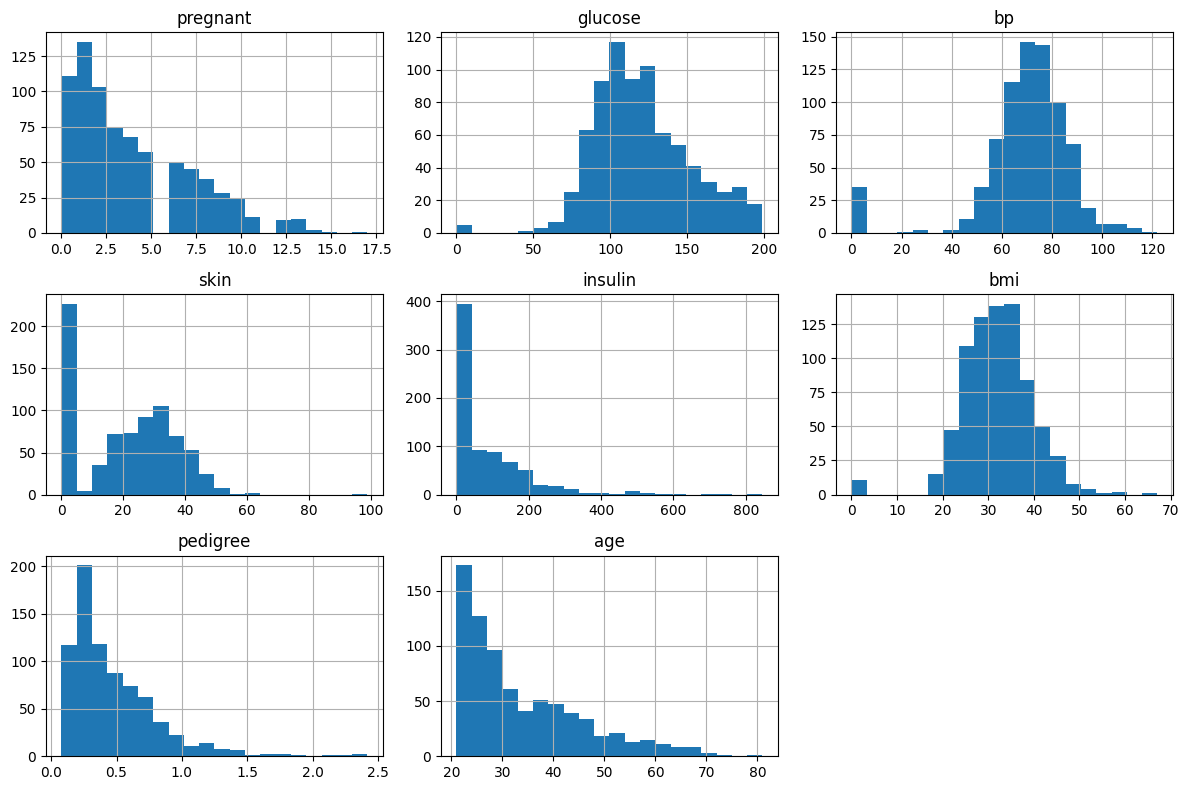

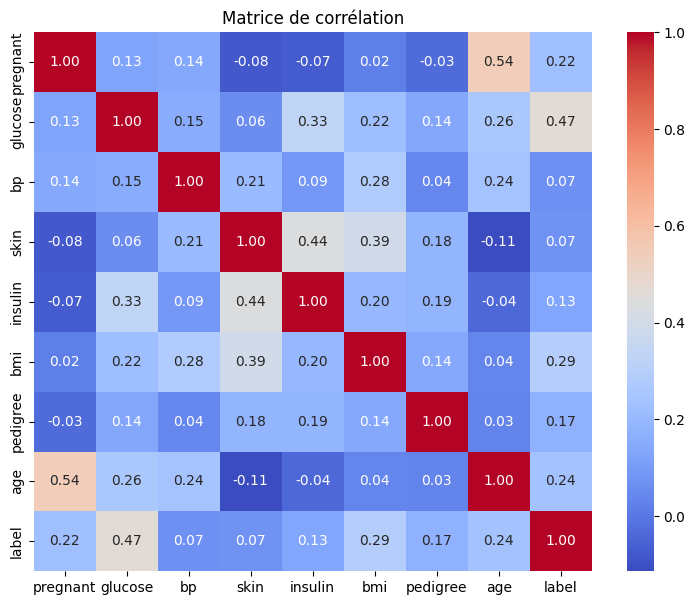

glucose      5
bp          35
skin       227
insulin    374
bmi         11
dtype: int64


In [3]:
# 1. Class distribution
sns.countplot(x='label', data=diabetes_data)
plt.title('Répartition des classes (0 = non diabétique, 1 = diabétique)'); plt.show()

# 2. Distribution of each variable
diabetes_data.drop(columns='label').hist(bins=20, figsize=(12, 8))
plt.tight_layout(); plt.show()

# 3. Correlations
plt.figure(figsize=(9, 7))
sns.heatmap(diabetes_data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matrice de corrélation'); plt.show()

# 4. Impossible zero values (= missing data)
print((diabetes_data[['glucose', 'bp', 'skin', 'insulin', 'bmi']] == 0).sum())

### Q9 b) Type du problème

Il s'agit d'une **classification supervisée binaire** : à partir de mesures médicales, on prédit une classe parmi deux (0 = non diabétique, 1 = diabétique). Les classes sont **déséquilibrées** (65 % / 35 %).

### Q9 c) Variables cibles et caractéristiques

- **Caractéristiques (X)** : `pregnant, glucose, bp, skin, insulin, bmi, pedigree, age` (8 variables).
- **Cible (Y)** : `label`.

In [4]:
feature_cols = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age']
X = diabetes_data[feature_cols]   # features
y = diabetes_data['label']        # target
print(X.shape, y.shape)           # (768, 8) (768,)

(768, 8) (768,)


### Q10 a) 
Découpage : **70 % apprentissage** (537 patientes) / **30 % test** (231 patientes). `random_state=1` rend le découpage reproductible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)


### Q10 b) Tree with the Gini index (default criterion)
L'arbre utilise l'**indice de Gini** : $\text{Gini} = 1 - \sum_k p_k^2$ (0 = nœud pur). Sans limite, il atteint une **profondeur de 16** avec **99 feuilles**, et obtient **100 %** sur l'apprentissage : il a mémorisé les données.


In [6]:

clf = DecisionTreeClassifier(random_state=1)
clf = clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Profondeur :", clf.get_depth(), "| Feuilles :", clf.get_n_leaves())
print("Accuracy train :", clf.score(X_train, y_train))

Profondeur : 16 | Feuilles : 99
Accuracy train : 1.0


### Q11) Évaluation

- **Accuracy test = 68,8 %**, contre 100 % en apprentissage → **sur-apprentissage**.
- Matrice de confusion : 116 VN, 30 FP, **42 FN**, 43 VP.
- **Rappel (diabétiques) = 43/85 ≈ 51 %** : la moitié des patientes diabétiques ne sont pas détectées, l'erreur la plus grave en médecine.
- Un modèle prédisant toujours « 0 » obtiendrait déjà ≈ 63 % : l'arbre n'apporte que peu d'amélioration.

In [7]:
print("Accuracy test :", metrics.accuracy_score(y_test, y_pred))
print(metrics.confusion_matrix(y_test, y_pred))

Accuracy test : 0.6883116883116883
[[116  30]
 [ 42  43]]


### Q12 a) Informations affichées dans chaque nœud

- **Condition de division** (ex. `glucose <= 129.5`) : vrai → branche gauche, faux → branche droite (absente dans les feuilles).
- **gini** : impureté du nœud (0 = pur).
- **samples** : nombre de patientes qui atteignent ce nœud.
- **value** : répartition par classe `[non diabétiques, diabétiques]`.
- **class** : classe majoritaire, prédite si le nœud est une feuille.
- **Couleur** : orange = classe 0, bleu = classe 1 ; plus la couleur est foncée, plus le nœud est pur.

Exemple, la racine : `glucose <= 129.5`, gini = 0,449, samples = 537, value = [354, 183], class = 0. Le **glucose** est bien la variable la plus discriminante, comme le laissait prévoir la matrice de corrélation.

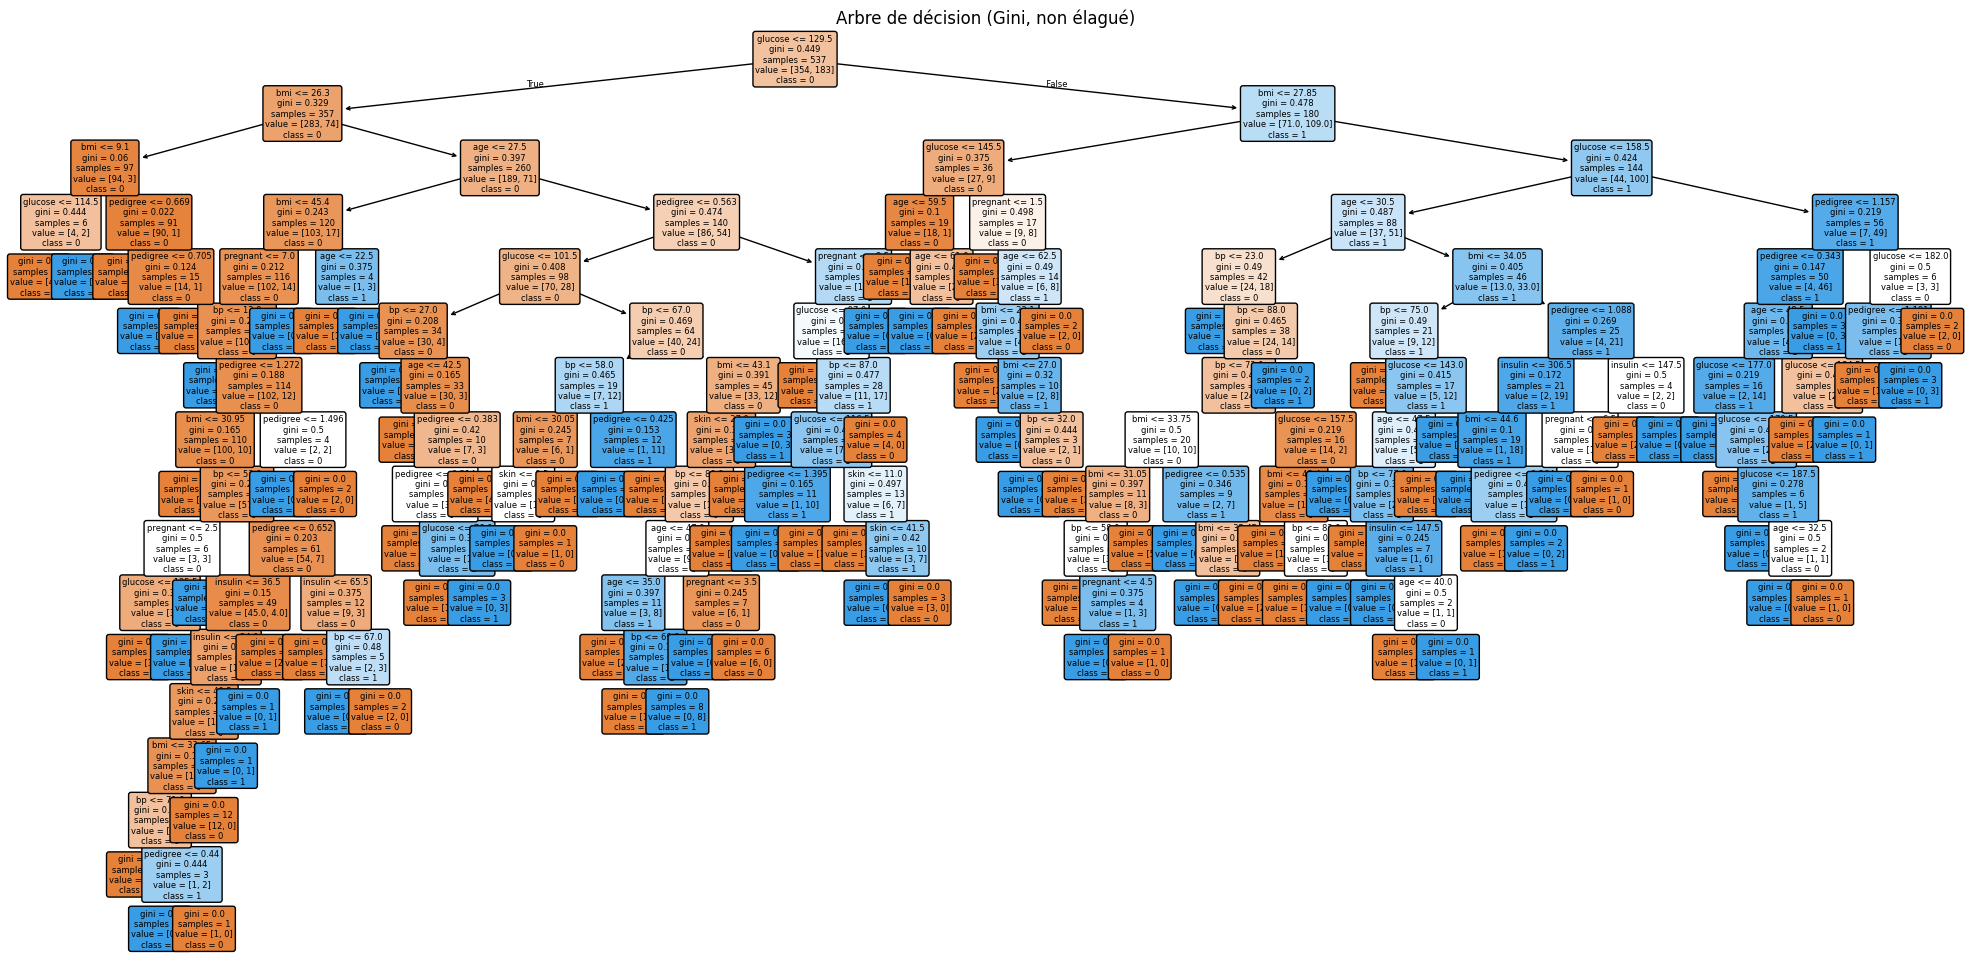

In [8]:
from sklearn.tree import plot_tree

plt.figure(figsize=(25, 12))
plot_tree(clf, feature_names=feature_cols, class_names=['0', '1'],
          filled=True, rounded=True, fontsize=6)
plt.title('Arbre de décision (Gini, non élagué)')
plt.savefig('diabetes.png', dpi=150, bbox_inches='tight')
plt.show()

### Q12 b) L'arbre est-il élagué ?

**Non.** L'arbre est développé jusqu'à ce que toutes les feuilles soient pures (gini = 0) : **profondeur 16, 99 feuilles**, dont 34 ne contiennent qu'**une seule patiente**. Ces règles très spécifiques ne se généralisent pas, d'où l'écart entre 100 % (apprentissage) et 68,8 % (test).
L'arbre apprend même des règles sur des valeurs aberrantes (ex. `bmi <= 9.1`, qui isole les IMC nuls, c'est-à-dire des données manquantes).

### Q13 a) Entropie et profondeur 3

- Critère **entropie** : $H = -\sum_k p_k \log_2 p_k$ (0 = nœud pur, 1 = mélange 50/50). L'arbre choisit la division qui maximise le **gain d'information**.
- Profondeur limitée à **3** (`max_depth=3`).
- Résultats : accuracy **76 % en apprentissage** et **77 % en test** ; matrice de confusion : 124 VN, 22 FP, 31 FN, 54 VP.

Accuracy train : 0.7635009310986964
Accuracy test  : 0.7705627705627706
[[124  22]
 [ 31  54]]


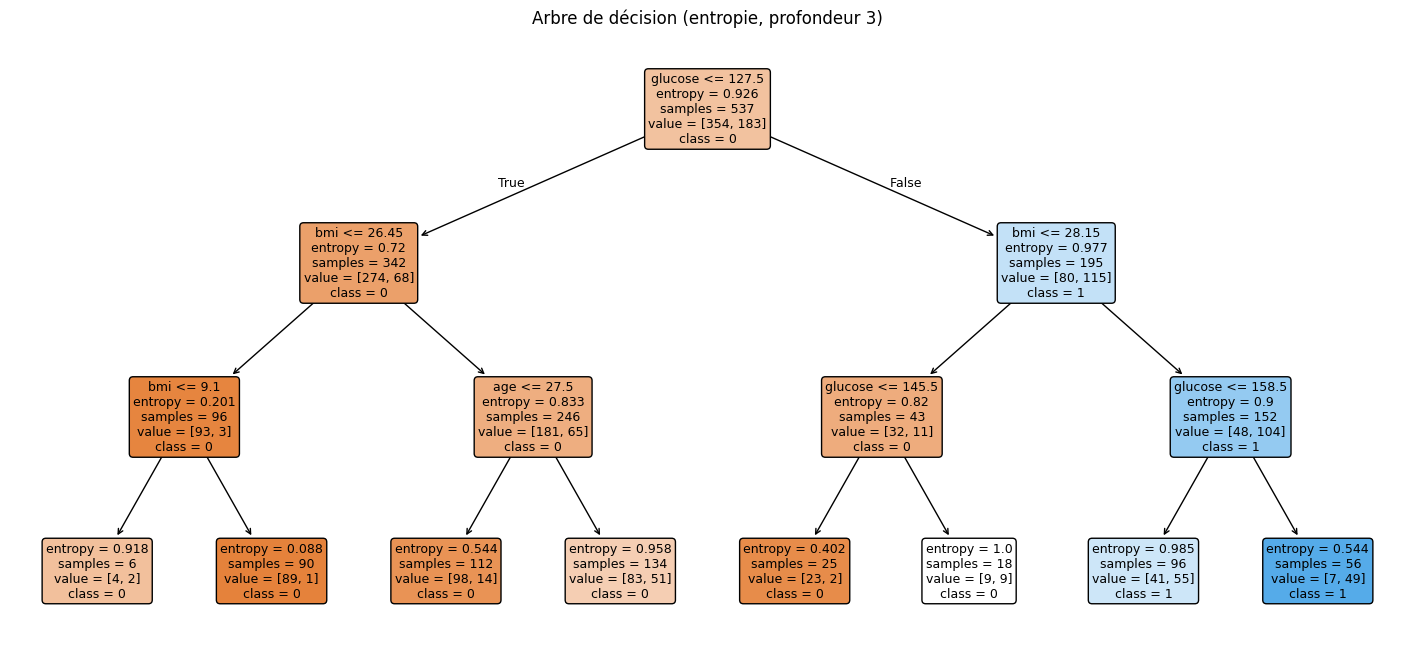

In [9]:
# Q13 a) Entropie + profondeur maximale 3
clf2 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
clf2 = clf2.fit(X_train, y_train)
y_pred2 = clf2.predict(X_test)

print("Accuracy train :", clf2.score(X_train, y_train))
print("Accuracy test  :", metrics.accuracy_score(y_test, y_pred2))
print(metrics.confusion_matrix(y_test, y_pred2))

# Q13 b) Nouveau graphique
plt.figure(figsize=(18, 8))
plot_tree(clf2, feature_names=feature_cols, class_names=['0', '1'],
          filled=True, rounded=True, fontsize=9)
plt.title('Arbre de décision (entropie, profondeur 3)')
plt.show()

### Q13 b) Constat

- Arbre **simple et lisible** : 3 niveaux, 8 feuilles (contre 16 niveaux et 99 feuilles).
- **Accuracy test : 77 %** contre 68,8 %, sans écart avec l'apprentissage → **plus de sur-apprentissage**.
- **Rappel (diabétiques) : 64 %** contre 51 % : plus de malades détectés.
- Même logique que l'arbre Gini : **glucose** à la racine, puis **IMC**.
- Règles interprétables, ex. : *glucose > 158,5 et IMC > 28,15 → diabétique* (49/56).
- Les feuilles ne sont plus pures : l'arbre accepte un peu d'erreur en apprentissage pour **mieux généraliser**.

### Q13 c) Pré-élagage ou post-élagage ?

C'est un **pré-élagage** : le paramètre `max_depth=3` arrête la croissance de l'arbre **pendant sa construction**, avant qu'il ne devienne trop profond.

À l'inverse, un **post-élagage** construit d'abord l'arbre complet, puis supprime les branches peu utiles (dans scikit-learn : paramètre `ccp_alpha`, élagage par coût-complexité).